# Interpretable Machine Learning for Inflammatory Monocyte States

This notebook tests whether transcriptomic features can distinguish inflammatory monocyte states from other monocyte states in the AMP RA Phase 1 single-cell dataset.

Inflammatory states are defined using published cell-state annotations:

- **SC-M1** — IL1B-positive pro-inflammatory monocytes
- **SC-M4** — interferon-activated monocytes

These are compared with:

- **SC-M2**
- **SC-M3**

A regularized logistic regression classifier is evaluated using **sample-aware cross-validation**, ensuring that cells from the same sequencing sample are not shared between training and validation folds.

Model-derived predictive genes are subsequently compared with candidates identified independently through differential expression, ranked GSEA, and leading-edge target prioritization in Notebook 01.

## 1. Setup

In [26]:
import sys
from pathlib import Path
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import scanpy as sc
import anndata as ad

# Machine learning
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    roc_auc_score,
    balanced_accuracy_score,
    confusion_matrix,
    RocCurveDisplay
)

np.random.seed(42)

print("Python:", sys.version.split()[0])
print("scikit-learn:", version("scikit-learn"))
print("Scanpy:", version("scanpy"))

Python: 3.12.15
scikit-learn: 1.9.1
Scanpy: 1.12.4


In [27]:
PROJECT_DIR = Path("..")

DATA_DIR = PROJECT_DIR / "data"
RESULTS_DIR = PROJECT_DIR / "results"
FIGURES_DIR = PROJECT_DIR / "figures"

RESULTS_DIR.mkdir(exist_ok=True)
FIGURES_DIR.mkdir(exist_ok=True)

## 2. Build the Monocyte Classification Dataset

The machine-learning analysis is restricted to the four published monocyte states (SC-M1–SC-M4).

The prediction target is defined as:

- **Inflammatory = 1:** SC-M1 and SC-M4
- **Other monocyte = 0:** SC-M2 and SC-M3

Sequencing sample identity is retained as the grouping variable for cross-validation to prevent cells from the same sample from appearing in both training and validation sets.

In [28]:
EXPR_FILE = DATA_DIR / "exprMatrix.tsv"
META_FILE = DATA_DIR / "meta"

# Load data
expr = pd.read_csv(
    EXPR_FILE,
    sep="\t"
)

meta = pd.read_csv(
    META_FILE,
    sep="\t"
)

# Convert expression matrix to cells × genes
expr_t = (
    expr
    .set_index("gene")
    .T
)

# Clean metadata and retain cells present in expression matrix
meta_clean = meta[
    meta["NAME"] != "TYPE"
].copy()

meta_clean = meta_clean[
    meta_clean["NAME"].isin(expr_t.index)
].copy()

# Extract sequencing sample
meta_clean["Sample"] = (
    meta_clean["NAME"]
    .str.split("_")
    .str[0]
)

meta_clean = (
    meta_clean
    .set_index("NAME")
    .loc[expr_t.index]
)

print("Expression matrix:", expr_t.shape)
print("Metadata:", meta_clean.shape)

Expression matrix: (5265, 29165)
Metadata: (5265, 2)


In [29]:
monocyte_clusters = [
    "SC-M1",
    "SC-M2",
    "SC-M3",
    "SC-M4"
]

monocyte_mask = meta_clean["Cluster"].isin(
    monocyte_clusters
)

mono_expr = expr_t.loc[monocyte_mask].copy()
mono_meta = meta_clean.loc[monocyte_mask].copy()

print("Monocyte cells:", len(mono_meta))
print("\nCells per monocyte state:")
print(mono_meta["Cluster"].value_counts().sort_index())

Monocyte cells: 750

Cells per monocyte state:
Cluster
SC-M1    349
SC-M2    237
SC-M3     93
SC-M4     71
Name: count, dtype: int64


In [30]:
mono_meta["Inflammatory"] = (
    mono_meta["Cluster"]
    .isin(["SC-M1", "SC-M4"])
    .astype(int)
)

print(
    mono_meta["Inflammatory"]
    .value_counts()
    .rename(index={
        0: "Other monocyte",
        1: "Inflammatory"
    })
)

print("\nSamples:", mono_meta["Sample"].nunique())

Inflammatory
Inflammatory      420
Other monocyte    330
Name: count, dtype: int64

Samples: 20


In [31]:
mono_adata = ad.AnnData(
    X=mono_expr,
    obs=mono_meta.copy()
)

print(mono_adata)

AnnData object with n_obs × n_vars = 750 × 29165
    obs: 'Cluster', 'Sample', 'Inflammatory'
    layers: None (.X)


In [32]:
sc.pp.highly_variable_genes(
    mono_adata,
    flavor="seurat",
    n_top_genes=1000
)

ml_genes = mono_adata.var_names[
    mono_adata.var["highly_variable"]
].tolist()

print("ML features selected:", len(ml_genes))

ML features selected: 1006


## 4. Sample-Aware Cross-Validation

To evaluate generalization across sequencing samples, model validation uses stratified group cross-validation.

- **Stratification** helps maintain the inflammatory/non-inflammatory class balance across folds.
- **Grouping by sample** ensures that cells from the same sequencing sample never appear in both training and validation sets.

This design reduces the risk that model performance is inflated by sample-specific transcriptional patterns.

In [33]:
X = mono_expr
y = mono_meta["Inflammatory"].to_numpy()
groups = mono_meta["Sample"].to_numpy()

print("Cells:", len(y))
print("Inflammatory:", (y == 1).sum())
print("Other monocytes:", (y == 0).sum())
print("Samples:", len(np.unique(groups)))

Cells: 750
Inflammatory: 420
Other monocytes: 330
Samples: 20


In [34]:
cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

fold_summary = []

for fold, (train_idx, test_idx) in enumerate(
    cv.split(X, y, groups),
    start=1
):
    train_samples = set(groups[train_idx])
    test_samples = set(groups[test_idx])

    # Critical leakage check
    overlap = train_samples.intersection(test_samples)

    fold_summary.append({
        "Fold": fold,
        "Train_cells": len(train_idx),
        "Test_cells": len(test_idx),
        "Train_samples": len(train_samples),
        "Test_samples": len(test_samples),
        "Train_inflammatory_pct": y[train_idx].mean(),
        "Test_inflammatory_pct": y[test_idx].mean(),
        "Sample_overlap": len(overlap)
    })

fold_summary = pd.DataFrame(fold_summary)

display(fold_summary)

,Fold,Train_cells,Test_cells,Train_samples,Test_samples,Train_inflammatory_pct,Test_inflammatory_pct,Sample_overlap
0,1,595,155,17,3,0.571429,0.516129,0
1,2,603,147,17,3,0.568823,0.523810,0
2,3,598,152,15,5,0.538462,0.644737,0
3,4,596,154,16,4,0.578859,0.487013,0
4,5,608,142,15,5,0.542763,0.633803,0


In [35]:
assert (fold_summary["Sample_overlap"] == 0).all()

print("Sample leakage check: PASSED")

Sample leakage check: PASSED


## 5. Cross-Validated Logistic Regression

A regularized logistic regression classifier was trained to distinguish inflammatory (SC-M1/SC-M4) from other (SC-M2/SC-M3) monocyte states.

To minimize information leakage, feature selection was repeated independently within each training fold:

1. select highly variable genes using training cells only,
2. standardize selected features using training data only,
3. fit logistic regression,
4. evaluate on completely held-out sequencing samples.

Performance was summarized using AUROC and balanced accuracy.

In [36]:
cv_results = []
fold_coefficients = []

for fold, (train_idx, test_idx) in enumerate(
    cv.split(X, y, groups),
    start=1
):

    # --------------------------------------------------
    # Split cells by sample-aware cross-validation
    # --------------------------------------------------
    X_train_full = X.iloc[train_idx]
    X_test_full = X.iloc[test_idx]

    y_train = y[train_idx]
    y_test = y[test_idx]

    # --------------------------------------------------
    # Feature selection using TRAINING CELLS ONLY
    # --------------------------------------------------
    train_adata = ad.AnnData(
        X=X_train_full
    )

    sc.pp.highly_variable_genes(
        train_adata,
        flavor="seurat",
        n_top_genes=1000
    )

    fold_genes = train_adata.var_names[
        train_adata.var["highly_variable"]
    ].tolist()

    X_train = X_train_full[fold_genes]
    X_test = X_test_full[fold_genes]

    # --------------------------------------------------
    # Scaling + regularized logistic regression
    # --------------------------------------------------
    model = Pipeline([
        (
            "scaler",
            StandardScaler()
        ),
        (
            "classifier",
            LogisticRegression(
                penalty="l2",
                class_weight="balanced",
                max_iter=5000,
                random_state=42
            )
        )
    ])

    model.fit(
        X_train,
        y_train
    )

    # --------------------------------------------------
    # Predictions on unseen samples
    # --------------------------------------------------
    y_prob = model.predict_proba(
        X_test
    )[:, 1]

    y_pred = model.predict(
        X_test
    )

    # --------------------------------------------------
    # Performance
    # --------------------------------------------------
    auc = roc_auc_score(
        y_test,
        y_prob
    )

    balanced_acc = balanced_accuracy_score(
        y_test,
        y_pred
    )

    cv_results.append({
        "Fold": fold,
        "N_train": len(train_idx),
        "N_test": len(test_idx),
        "N_features": len(fold_genes),
        "AUROC": auc,
        "Balanced_Accuracy": balanced_acc
    })

    # --------------------------------------------------
    # Save gene coefficients
    # --------------------------------------------------
    coefficients = model[
        "classifier"
    ].coef_[0]

    fold_coef = pd.DataFrame({
        "Gene": fold_genes,
        "Coefficient": coefficients,
        "Fold": fold
    })

    fold_coefficients.append(
        fold_coef
    )

cv_results = pd.DataFrame(
    cv_results
)

display(cv_results)

/Users/jacklyn/miniforge3/envs/single-cell-ra/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/jacklyn/miniforge3/envs/single-cell-ra/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.wa

,Fold,N_train,N_test,N_features,AUROC,Balanced_Accuracy
0,1,595,155,1000,0.944333,0.845000
1,2,603,147,1002,0.903340,0.790909
2,3,598,152,1000,0.880574,0.792895
3,4,596,154,1000,0.926245,0.830717
4,5,608,142,1000,0.939530,0.846795


In [37]:
print(
    "Mean AUROC:",
    round(cv_results["AUROC"].mean(), 3)
)

print(
    "AUROC SD:",
    round(cv_results["AUROC"].std(), 3)
)

print(
    "Mean balanced accuracy:",
    round(
        cv_results["Balanced_Accuracy"].mean(),
        3
    )
)

print(
    "Balanced accuracy SD:",
    round(
        cv_results["Balanced_Accuracy"].std(),
        3
    )
)

Mean AUROC: 0.919
AUROC SD: 0.027
Mean balanced accuracy: 0.821
Balanced accuracy SD: 0.028


## 6. Interpretable ML Feature Analysis

Logistic-regression coefficients were examined to identify transcriptomic features associated with inflammatory monocyte classification.

Because highly variable genes were selected independently within each training fold, the feature sets differed slightly across folds. Gene coefficients were therefore aggregated across cross-validation folds to identify features that were repeatedly selected and showed consistent directional effects.

Positive coefficients indicate association with the inflammatory monocyte class, whereas negative coefficients indicate association with the other monocyte class.

In [38]:
all_coefficients = pd.concat(
    fold_coefficients,
    ignore_index=True
)

gene_coefficients = (
    all_coefficients
    .groupby("Gene")
    .agg(
        Mean_Coefficient=("Coefficient", "mean"),
        SD_Coefficient=("Coefficient", "std"),
        N_Folds=("Fold", "nunique")
    )
    .reset_index()
)

gene_coefficients["Abs_Mean_Coefficient"] = (
    gene_coefficients["Mean_Coefficient"].abs()
)

In [39]:
stable_ml_features = (
    gene_coefficients[
        gene_coefficients["N_Folds"] == 5
    ]
    .sort_values(
        "Abs_Mean_Coefficient",
        ascending=False
    )
)

print(
    "Genes selected in all 5 folds:",
    len(stable_ml_features)
)

display(
    stable_ml_features.head(20)
)

Genes selected in all 5 folds: 223


,Gene,Mean_Coefficient,SD_Coefficient,N_Folds,Abs_Mean_Coefficient
583,HSPD1,0.372491,0.032983,5,0.372491
354,CTSK,-0.331137,0.048459,5,0.331137
573,HSP90AA1,0.306586,0.076405,5,0.306586
630,IL1B,0.283226,0.090344,5,0.283226
633,IL1RN,0.268663,0.045589,5,0.268663
917,PLA2G4C,0.260634,0.079605,5,0.260634
107,ANKRD37,0.256922,0.047647,5,0.256922
470,FCN1,0.252780,0.045027,5,0.252780
356,CXADR,-0.247428,0.059085,5,0.247428
362,CXCL3,0.246112,0.076162,5,0.246112


## 7. Convergent Evidence with Target Discovery

Machine-learning features were compared with candidate genes identified independently in Notebook 01 through differential expression, ranked GSEA, leading-edge analysis, and cross-cell-state prioritization.

This comparison is used to identify genes supported by both:

1. **biological/pathway evidence**, and
2. **predictive inflammatory-state evidence**.

Because both analyses use the same underlying single-cell dataset, this represents orthogonal computational evidence rather than independent external validation.

In [40]:
target_table = pd.read_csv(
    RESULTS_DIR / "gene_level_target_prioritization.csv"
)

mechanism_targets = pd.read_csv(
    RESULTS_DIR / "mechanism_focused_candidate_targets.csv"
)

print("Target-discovery candidates:", len(target_table))
print("Mechanism-focused candidates:", len(mechanism_targets))

Target-discovery candidates: 673
Mechanism-focused candidates: 18


In [41]:
inflammatory_ml_features = (
    stable_ml_features[
        stable_ml_features["Mean_Coefficient"] > 0
    ]
    .copy()
)

print(
    "Stable inflammatory ML features:",
    len(inflammatory_ml_features)
)

Stable inflammatory ML features: 130


In [42]:
convergent_candidates = (
    inflammatory_ml_features
    .merge(
        target_table[
            [
                "Gene",
                "Transcriptomic_Evidence_Score",
                "Cross_Cluster_Count",
                "Total_Pathway_Count",
                "Clusters"
            ]
        ],
        on="Gene",
        how="inner"
    )
    .sort_values(
        "Abs_Mean_Coefficient",
        ascending=False
    )
)

print(
    "Genes supported by both ML and target-discovery analyses:",
    len(convergent_candidates)
)

display(
    convergent_candidates.head(25)
)

Genes supported by both ML and target-discovery analyses: 25


,Gene,Mean_Coefficient,SD_Coefficient,N_Folds,Abs_Mean_Coefficient,Transcriptomic_Evidence_Score,Cross_Cluster_Count,Total_Pathway_Count,Clusters
0,HSPD1,0.372491,0.032983,5,0.372491,0.141601,1,7,SC-M1
1,IL1B,0.283226,0.090344,5,0.283226,0.320161,2,17,SC-M1;SC-M4
2,IL1RN,0.268663,0.045589,5,0.268663,0.245942,2,2,SC-M1;SC-M4
3,PLA2G4C,0.260634,0.079605,5,0.260634,0.178521,2,3,SC-M1;SC-M4
4,FCN1,0.252780,0.045027,5,0.252780,0.219611,2,4,SC-M1;SC-M4
5,CXCL3,0.246112,0.076162,5,0.246112,0.075850,1,2,SC-M4
6,C3,0.244086,0.042783,5,0.244086,0.021198,1,1,SC-M1
7,GBP5,0.207432,0.062159,5,0.207432,0.177433,2,9,SC-M1;SC-M4
8,BIRC3,0.203880,0.076871,5,0.203880,0.076542,1,1,SC-B3
9,EREG,0.187756,0.039410,5,0.187756,0.196803,2,6,SC-M1;SC-M4


In [43]:
monocyte_target_candidates = (
    pd.read_csv(
        RESULTS_DIR / "cell_state_candidate_genes.csv"
    )
)

monocyte_target_candidates = (
    monocyte_target_candidates[
        monocyte_target_candidates["Cluster"].isin(
            ["SC-M1", "SC-M4"]
        )
    ]
)

monocyte_candidate_genes = set(
    monocyte_target_candidates["Gene"]
)

print(
    "Notebook 01 monocyte candidate genes:",
    len(monocyte_candidate_genes)
)

Notebook 01 monocyte candidate genes: 487


In [44]:
convergent_monocyte_genes = (
    inflammatory_ml_features[
        inflammatory_ml_features["Gene"].isin(
            monocyte_candidate_genes
        )
    ]
    .merge(
        target_table[
            [
                "Gene",
                "Transcriptomic_Evidence_Score",
                "Cross_Cluster_Count",
                "Total_Pathway_Count",
                "Clusters"
            ]
        ],
        on="Gene",
        how="left"
    )
    .sort_values(
        "Abs_Mean_Coefficient",
        ascending=False
    )
)

print(
    "Convergent inflammatory-monocyte genes:",
    len(convergent_monocyte_genes)
)

display(
    convergent_monocyte_genes.head(25)
)

Convergent inflammatory-monocyte genes: 21


,Gene,Mean_Coefficient,SD_Coefficient,N_Folds,Abs_Mean_Coefficient,Transcriptomic_Evidence_Score,Cross_Cluster_Count,Total_Pathway_Count,Clusters
0,HSPD1,0.372491,0.032983,5,0.372491,0.141601,1,7,SC-M1
1,IL1B,0.283226,0.090344,5,0.283226,0.320161,2,17,SC-M1;SC-M4
2,IL1RN,0.268663,0.045589,5,0.268663,0.245942,2,2,SC-M1;SC-M4
3,PLA2G4C,0.260634,0.079605,5,0.260634,0.178521,2,3,SC-M1;SC-M4
4,FCN1,0.252780,0.045027,5,0.252780,0.219611,2,4,SC-M1;SC-M4
5,CXCL3,0.246112,0.076162,5,0.246112,0.075850,1,2,SC-M4
6,C3,0.244086,0.042783,5,0.244086,0.021198,1,1,SC-M1
7,GBP5,0.207432,0.062159,5,0.207432,0.177433,2,9,SC-M1;SC-M4
8,EREG,0.187756,0.039410,5,0.187756,0.196803,2,6,SC-M1;SC-M4
9,CXCL10,0.186339,0.058405,5,0.186339,0.201110,2,11,SC-M1;SC-M4


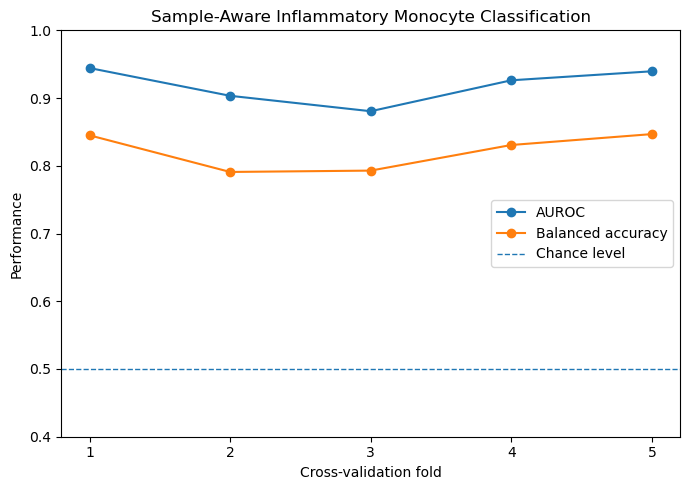

In [ ]:
fig, ax = plt.subplots(figsize=(7, 5))

x = np.arange(1, len(cv_results) + 1)

ax.plot(
    x,
    cv_results["AUROC"],
    marker="o",
    label="AUROC"
)

ax.plot(
    x,
    cv_results["Balanced_Accuracy"],
    marker="o",
    label="Balanced accuracy"
)

ax.axhline(
    0.5,
    linestyle="--",
    linewidth=1,
    label="Chance level"
)

ax.set_xticks(x)
ax.set_xlabel("Cross-validation fold")
ax.set_ylabel("Performance")
ax.set_ylim(0.4, 1.0)

ax.set_title(
    "Sample-Aware Inflammatory Monocyte Classification"
)

ax.legend()

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "09_ml_cross_validation_performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

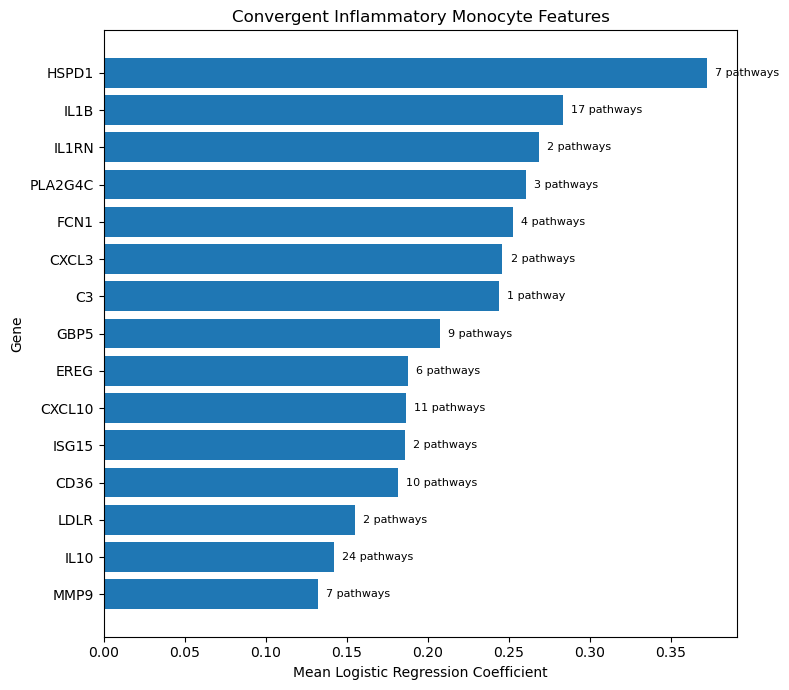

In [ ]:
plot_genes = (
    convergent_monocyte_genes
    .head(15)
    .sort_values(
        "Mean_Coefficient",
        ascending=True
    )
)

fig, ax = plt.subplots(figsize=(8, 7))

bars = ax.barh(
    plot_genes["Gene"],
    plot_genes["Mean_Coefficient"]
)

ax.set_xlabel("Mean Logistic Regression Coefficient")
ax.set_ylabel("Gene")
ax.set_title("Convergent Inflammatory Monocyte Features")

for bar, pathway_count in zip(
    bars,
    plot_genes["Total_Pathway_Count"]
):
    pathway_count = int(pathway_count)

    label = (
        f"{pathway_count} pathway"
        if pathway_count == 1
        else f"{pathway_count} pathways"
    )

    ax.text(
        bar.get_width() + 0.005,
        bar.get_y() + bar.get_height() / 2,
        label,
        va="center",
        fontsize=8
    )

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "10_ml_convergent_monocyte_features.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 8. Export Results

Cross-validation performance, stable model features, and genes supported by both machine-learning and pathway-based analyses are exported for downstream interpretation and reproducibility.

In [47]:
cv_results.to_csv(
    RESULTS_DIR / "ml_cross_validation_performance.csv",
    index=False
)

gene_coefficients.to_csv(
    RESULTS_DIR / "ml_gene_coefficients.csv",
    index=False
)

stable_ml_features.to_csv(
    RESULTS_DIR / "ml_stable_features.csv",
    index=False
)

convergent_monocyte_genes.to_csv(
    RESULTS_DIR / "ml_convergent_monocyte_genes.csv",
    index=False
)

print("Machine-learning results exported successfully.")

Machine-learning results exported successfully.


## 9. Results Summary

A sample-aware regularized logistic regression classifier was trained to distinguish inflammatory monocyte states (SC-M1 and SC-M4) from other monocyte states (SC-M2 and SC-M3).

The analysis included **750 monocytes from 20 sequencing samples**. Five-fold stratified group cross-validation ensured that cells from the same sequencing sample were never shared between training and validation sets. Highly variable genes were selected independently within each training fold to minimize information leakage.

### Model Performance

The classifier achieved:

- **Mean AUROC: 0.919 ± 0.027**
- **Mean balanced accuracy: 0.821 ± 0.028**

Performance remained consistent across held-out sample folds, indicating that inflammatory monocyte states contain reproducible transcriptional features that generalize across sequencing samples.

### Interpretable ML Features

Logistic-regression coefficients were aggregated across cross-validation folds to identify stable predictive features.

Positive coefficients represent genes associated with the inflammatory monocyte class, while negative coefficients represent genes associated with other monocyte states.

### Convergent Computational Evidence

Stable inflammatory ML features were compared with SC-M1/SC-M4 candidate genes identified independently in Notebook 01 through differential expression, ranked GSEA, and leading-edge analysis.

This comparison identified **21 convergent genes** supported by both predictive and pathway-level evidence, including:

**IL1B, IL1RN, FCN1, CXCL3, GBP5, CXCL10, ISG15, CD36, IL10, MMP9, and RSAD2.**

The two analyses address complementary questions:

- **Notebook 01:** Which genes repeatedly contribute to disease-relevant biological pathways?
- **Notebook 02:** Which genes help distinguish inflammatory monocyte states across held-out samples?

Their overlap therefore represents **convergent computational evidence**, not independent biological or clinical validation.

Importantly, predictive ML features should not be interpreted directly as therapeutic targets. A gene can be highly predictive of a cellular state without being causal, druggable, or therapeutically beneficial.